# 02 · Development EDA and modeling hypotheses
## Summary
Answer modeling questions using observations strictly before the configured test start. Calendar profiles, holidays, thermal response, lagged temperature and structural changes are descriptive; they do not prove causal mechanisms or forecast availability. The legacy full-history results remain exposed and are not relabeled as development-only evidence.
## Context and methods
Target: national demand in MW. Local calendar: Europe/Paris. Development excludes delivery dates from 2025-07-01 onward. Holidays cover metropolitan national public holidays, not school calendars or regional exceptions.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/forecast_contract.json").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.common import load_contract, prepare_directories, plotting_style, write_json, fingerprint
contract = load_contract(ROOT)
prepare_directories(ROOT)
plotting_style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 16)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
from src.data import read_audited
from src.eda import development_frame, temperature_summary, hypothesis_register
data = read_audited(ROOT)
dev = development_frame(data, contract)
dev["rte_error_mw"] = dev.load_mw-dev.rte_forecast_d1_mw
display(pd.Series({"development_start_UTC":dev.index.min(),"development_end_UTC":dev.index.max(),"rows":len(dev),"missing_demand":int(dev.load_mw.isna().sum())}).to_frame("scope"))

,scope
development_start_UTC,2019-01-01 00:00:00+00:00
development_end_UTC,2025-06-30 21:00:00+00:00
rows,56950
missing_demand,6


### 1. Do seasonal and weekday profiles differ?

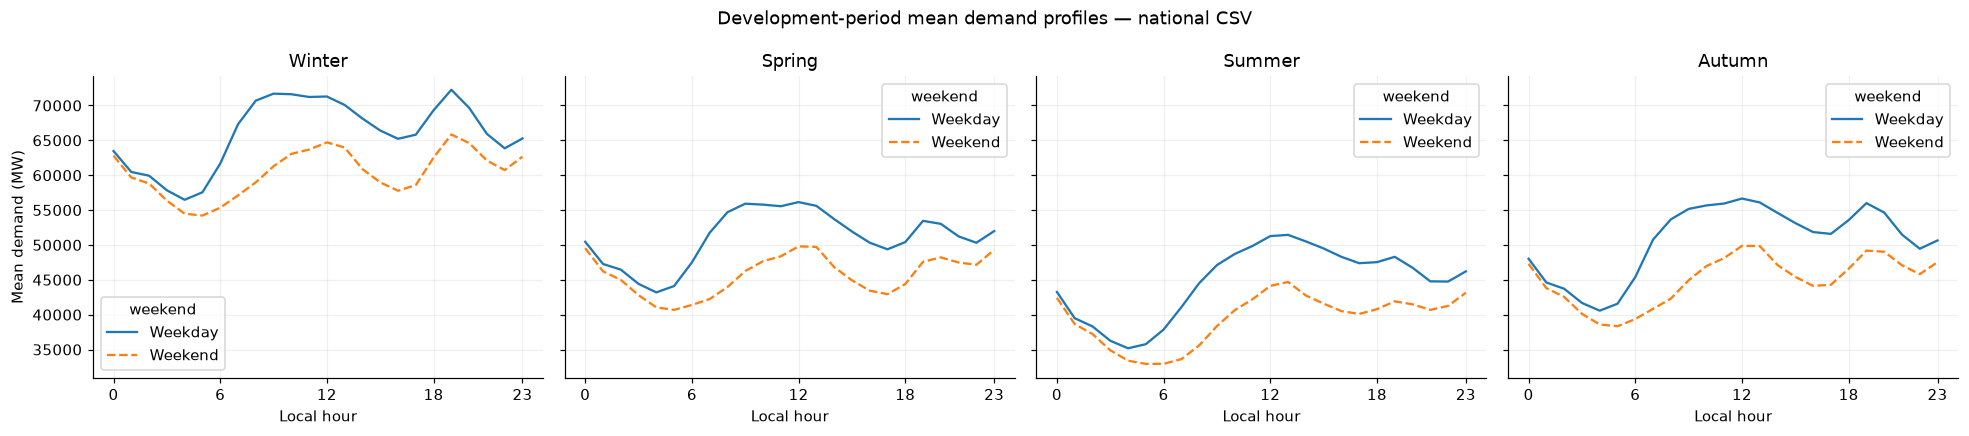

In [3]:
profiles = dev.groupby(["season","hour","weekend"]).load_mw.mean()
fig, axes = plt.subplots(1,4,figsize=(18,4),sharex=True,sharey=True)
for ax, season in zip(axes,["Winter","Spring","Summer","Autumn"]):
    profiles.loc[season].unstack("weekend").rename(columns={0:"Weekday",1:"Weekend"}).plot(ax=ax,title=season,style=["-","--"])
    ax.set(xlabel="Local hour",xticks=[0,6,12,18,23])
axes[0].set_ylabel("Mean demand (MW)")
fig.suptitle("Development-period mean demand profiles — national CSV")
plt.tight_layout(); plt.show()

### 2. Holidays and annual structural changes

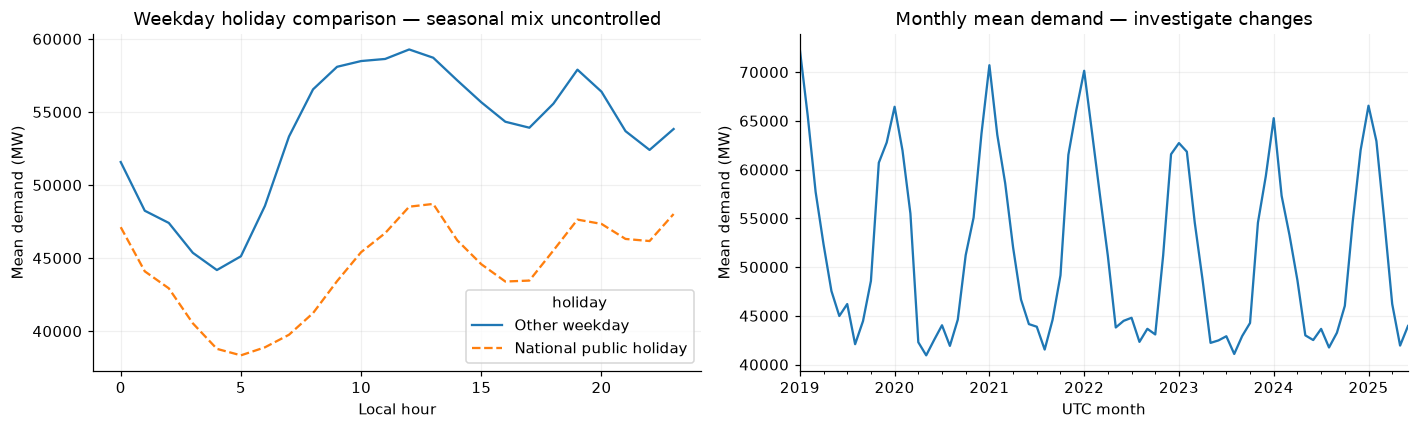

mean  count
year holiday                  
2021 0       53,672.079   8495
     1       47,714.777    264
2022 0       51,683.993   8495
     1       41,858.451    264
2023 0       49,957.083   8495
     1       42,206.697    264
2024 0       50,294.814   8519
     1       43,855.076    264
2025 0       52,971.766   4199
     1       43,426.049    144

In [4]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
dev.loc[dev.weekend.eq(0)].groupby(["hour","holiday"]).load_mw.mean().unstack("holiday").rename(columns={0:"Other weekday",1:"National public holiday"}).plot(ax=axes[0],style=["-","--"])
axes[0].set(title="Weekday holiday comparison — seasonal mix uncontrolled",xlabel="Local hour",ylabel="Mean demand (MW)")
dev.load_mw.resample("MS").mean().plot(ax=axes[1])
axes[1].set(title="Monthly mean demand — investigate changes",xlabel="UTC month",ylabel="Mean demand (MW)")
plt.tight_layout(); plt.show()
display(dev.groupby(["year","holiday"]).load_mw.agg(["mean","count"]).tail(10))

### 3. Temperature response and sparse extreme bands

,band_check
eligible,430
excluded_missing,0
unassigned_bins,0


,median_load_MW,bias_MW,MAE_MW,observations
temperature_band,,,,
"[-4.0, -2.0)","80,316.000","4,278.000","4,278.000",1
"[-2.0, 0.0)","84,145.500","2,756.875","2,756.875",8
"[0.0, 2.0)","82,087.500","1,019.526","1,288.632",38
"[2.0, 4.0)","79,854.000","1,106.953","1,364.828",64
"[4.0, 6.0)","74,496.000",623.969,"1,143.262",65
"[6.0, 8.0)","71,800.000",659.140,"1,223.828",93
"[8.0, 10.0)","68,321.000",406.890,"1,157.637",91
"[10.0, 12.0)","65,524.000",305.909,"1,242.855",55
"[12.0, 14.0)","61,729.500",761.643,"1,719.786",14


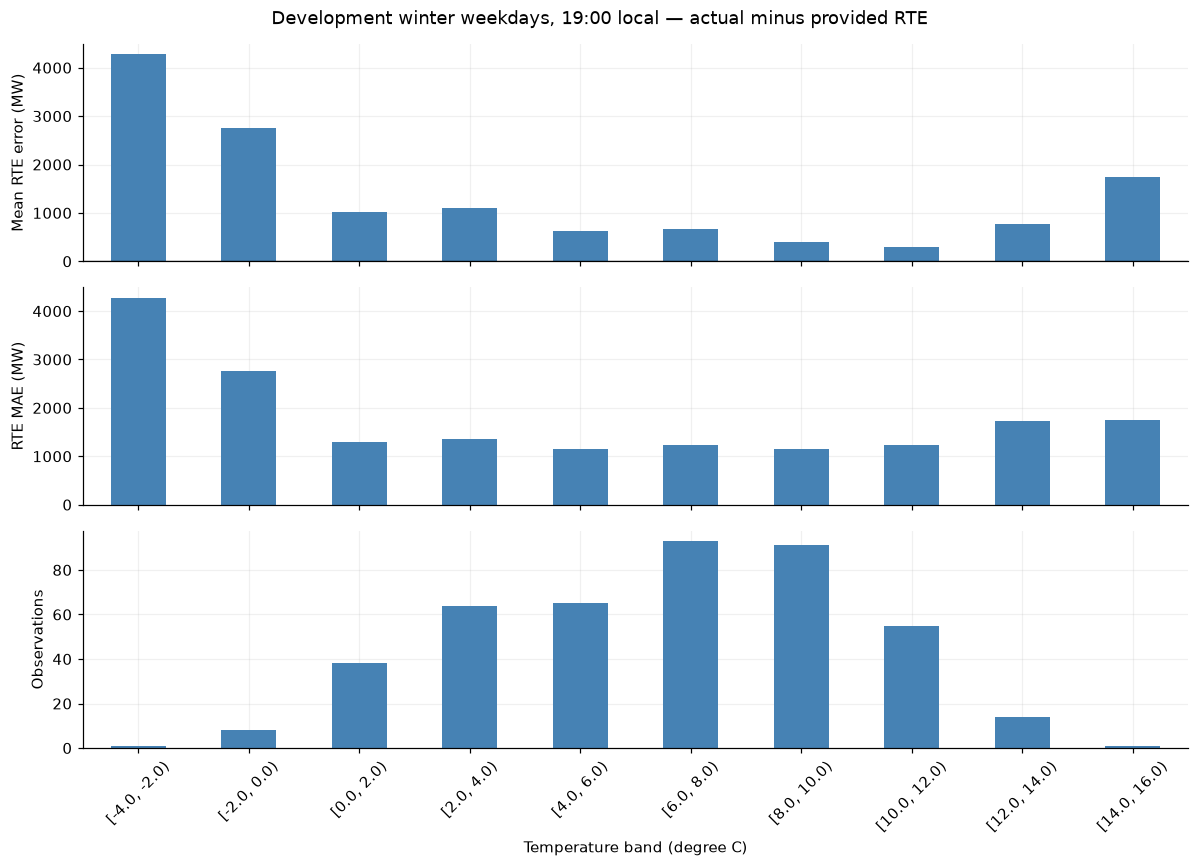

In [5]:
sample = dev.loc[dev.season.eq("Winter") & dev.weekend.eq(0) & dev.hour.eq(19)]
temperature_table, band_checks = temperature_summary(sample)
display(pd.Series(band_checks).to_frame("band_check")); display(temperature_table)
temperature_table.to_csv(ROOT/"reports/scorecards/development_temperature_bands.csv")
fig, axes = plt.subplots(3,1,figsize=(11,8),sharex=True)
for ax,col,label in zip(axes,["bias_MW","MAE_MW","observations"],["Mean RTE error (MW)","RTE MAE (MW)","Observations"]):
    temperature_table[col].plot.bar(ax=ax,color="steelblue")
    ax.set_ylabel(label)
axes[0].axhline(0,color="black",linewidth=.8)
axes[2].set_xlabel("Temperature band (degree C)")
axes[2].tick_params(axis="x",labelrotation=45)
fig.suptitle("Development winter weekdays, 19:00 local — actual minus provided RTE")
plt.tight_layout(); plt.show()

### 4. Delayed temperature and changing RTE bias

,load_mw
temperature_c,-0.763
load_mw,1.000
temperature_previous_24h,-0.796
temperature_lag_24h,-0.773


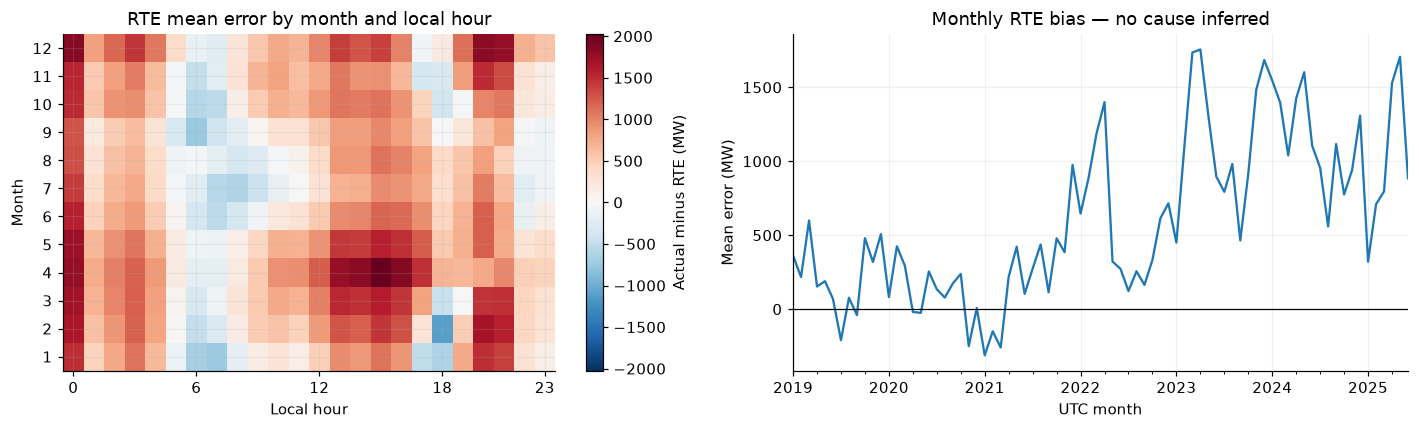

In [6]:
thermal = dev[["temperature_c","load_mw"]].copy()
thermal["temperature_previous_24h"] = thermal.temperature_c.shift(1).rolling(24,min_periods=24).mean()
thermal["temperature_lag_24h"] = thermal.temperature_c.shift(24)
display(thermal.loc[sample.index].corr()[["load_mw"]])
fig, axes = plt.subplots(1,2,figsize=(13,4))
matrix=dev.groupby(["month","hour"]).rte_error_mw.mean().unstack("hour")
bound=np.nanmax(np.abs(matrix.to_numpy()))
im=axes[0].imshow(matrix,aspect="auto",origin="lower",cmap="RdBu_r",vmin=-bound,vmax=bound)
axes[0].set(title="RTE mean error by month and local hour",xlabel="Local hour",ylabel="Month",yticks=range(12),yticklabels=range(1,13),xticks=[0,6,12,18,23])
fig.colorbar(im,ax=axes[0],label="Actual minus RTE (MW)")
dev.rte_error_mw.resample("MS").mean().plot(ax=axes[1])
axes[1].axhline(0,color="black",linewidth=.8)
axes[1].set(title="Monthly RTE bias — no cause inferred",ylabel="Mean error (MW)",xlabel="UTC month")
plt.tight_layout(); plt.show()

## Takeaways: hypotheses, not automatic features
The diagnostic lagged-temperature columns above are aligned to delivery time. They are not blindly reused as next-day predictors: the replay engine reconstructs historical temperature summaries at the origin cutoff instead. Correlations can mix season, year, holidays and economic conditions. No universal differencing/stationarity prerequisite is imposed.

In [7]:
hypotheses = hypothesis_register()
hypotheses.to_csv(ROOT/"reports/hypothesis_register.csv",index=False)
display(hypotheses)

,id,question,feature,experiment,status
0,H1,Do calendar cycles explain demand?,hour/weekend/season/public holiday interactions,calendar,test on chronological validation
1,H2,Does recent demand track structural changes?,known weekly lags and pre-cutoff rolling summa...,history_365 versus calendar,test on chronological validation
2,H3,Does prior temperature add thermal-memory info...,last available temperature and past 24h mean,history_past_weather,observation vintage approximation applies
3,H4,Does cold-evening RTE bias recur?,pre-cutoff calendar/history and historical errors,rte_correction_proxy versus rte_bias_proxy,RTE vintage unverified; retrospective only
4,H5,Does authentic weather improve operational for...,"archived forecast run, lead time, heating/cool...",weather_archive,gated: archive missing
5,H6,How sensitive is skill to future weather knowl...,recorded delivery-temperature heating/cooling ...,oracle_weather_sensitivity,oracle; never eligible for selection/deployment
